In [1]:
import pandas as pd

df = pd.read_excel('/content/Online Retail.xlsx')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Dataset Information
print("DATASET INFORMATION")
print("-" * 50)

df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nCountries in Dataset:")
print(df['Country'].nunique())

print("\nTop 10 Countries by Transactions:")
print(df['Country'].value_counts().head(10))

DATASET INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records:
5268

Count

In [3]:
# Step 3: Filter United Kingdom Transactions

df_uk = df[df['Country'] == 'United Kingdom'].copy()

print("UK DATASET CREATED SUCCESSFULLY!")
print("-" * 45)

print("Original Dataset Rows:", len(df))
print("UK Transaction Rows:", len(df_uk))

print("Unique UK Invoices:", df_uk['InvoiceNo'].nunique())
print("Unique UK Products:", df_uk['Description'].nunique())

print("\nCountry Verification:")
print(df_uk['Country'].value_counts())

df_uk.head()

UK DATASET CREATED SUCCESSFULLY!
---------------------------------------------
Original Dataset Rows: 541909
UK Transaction Rows: 495478
Unique UK Invoices: 23494
Unique UK Products: 4202

Country Verification:
Country
United Kingdom    495478
Name: count, dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# Step 4: Remove Cancelled Invoices

rows_before = len(df_uk)

df_uk = df_uk[
    ~df_uk['InvoiceNo'].astype(str).str.startswith('C')
].copy()

rows_after = len(df_uk)

print("CANCELLED INVOICES REMOVED")
print("-" * 40)
print("Rows Before:", rows_before)
print("Rows After:", rows_after)
print("Rows Removed:", rows_before - rows_after)
print("Remaining Unique Invoices:", df_uk['InvoiceNo'].nunique())

CANCELLED INVOICES REMOVED
----------------------------------------
Rows Before: 495478
Rows After: 487622
Rows Removed: 7856
Remaining Unique Invoices: 20122


In [5]:
# Step 5: Remove Returns and Invalid Transactions

rows_before = len(df_uk)

df_uk = df_uk[
    (df_uk['Quantity'] > 0) &
    (df_uk['UnitPrice'] > 0)
].copy()

rows_after = len(df_uk)

print("RETURNS AND INVALID TRANSACTIONS REMOVED")
print("-" * 50)
print("Rows Before:", rows_before)
print("Rows After:", rows_after)
print("Rows Removed:", rows_before - rows_after)

print("\nRemaining Negative Quantities:",
      (df_uk['Quantity'] <= 0).sum())

print("Remaining Invalid Prices:",
      (df_uk['UnitPrice'] <= 0).sum())

RETURNS AND INVALID TRANSACTIONS REMOVED
--------------------------------------------------
Rows Before: 487622
Rows After: 485123
Rows Removed: 2499

Remaining Negative Quantities: 0
Remaining Invalid Prices: 0


In [6]:
# Step 6: Remove Missing Product Descriptions

rows_before = len(df_uk)

df_uk = df_uk.dropna(subset=['Description']).copy()

rows_after = len(df_uk)

print("MISSING DESCRIPTIONS HANDLED")
print("-" * 45)
print("Rows Before:", rows_before)
print("Rows After:", rows_after)
print("Rows Removed:", rows_before - rows_after)

print("\nRemaining Missing Descriptions:",
      df_uk['Description'].isnull().sum())

MISSING DESCRIPTIONS HANDLED
---------------------------------------------
Rows Before: 485123
Rows After: 485123
Rows Removed: 0

Remaining Missing Descriptions: 0


In [7]:
# Step 7: Standardize Product Names

df_uk['Description'] = (
    df_uk['Description']
    .str.strip()
    .str.upper()
)

print("PRODUCT NAMES STANDARDIZED SUCCESSFULLY!")

print("\nSample Product Names:")
print(df_uk['Description'].head(10))

print("\nUnique Products:", df_uk['Description'].nunique())

PRODUCT NAMES STANDARDIZED SUCCESSFULLY!

Sample Product Names:
0     WHITE HANGING HEART T-LIGHT HOLDER
1                    WHITE METAL LANTERN
2         CREAM CUPID HEARTS COAT HANGER
3    KNITTED UNION FLAG HOT WATER BOTTLE
4         RED WOOLLY HOTTIE WHITE HEART.
5           SET 7 BABUSHKA NESTING BOXES
6      GLASS STAR FROSTED T-LIGHT HOLDER
7                 HAND WARMER UNION JACK
8              HAND WARMER RED POLKA DOT
9          ASSORTED COLOUR BIRD ORNAMENT
Name: Description, dtype: object

Unique Products: 3996


In [8]:
# Step 8: Remove Duplicate Records

rows_before = len(df_uk)

duplicates = df_uk.duplicated().sum()

df_uk = df_uk.drop_duplicates().copy()

rows_after = len(df_uk)

print("DUPLICATE RECORDS REMOVED")
print("-" * 45)
print("Duplicate Records Found:", duplicates)
print("Rows Before:", rows_before)
print("Rows After:", rows_after)
print("Rows Removed:", rows_before - rows_after)

print("\nRemaining Duplicates:", df_uk.duplicated().sum())

DUPLICATE RECORDS REMOVED
---------------------------------------------
Duplicate Records Found: 5138
Rows Before: 485123
Rows After: 479985
Rows Removed: 5138

Remaining Duplicates: 0


In [9]:
# Step 9: Remove Non-Product Entries

rows_before = len(df_uk)

non_product_codes = ['POST', 'M']

df_uk = df_uk[
    ~df_uk['StockCode'].astype(str).str.upper().isin(non_product_codes)
].copy()

rows_after = len(df_uk)

print("NON-PRODUCT ENTRIES REMOVED")
print("-" * 45)
print("Rows Before:", rows_before)
print("Rows After:", rows_after)
print("Rows Removed:", rows_before - rows_after)

print("\nRemaining Non-Product Codes:")
print(df_uk[
    df_uk['StockCode'].astype(str).str.upper().isin(non_product_codes)
].shape[0])

NON-PRODUCT ENTRIES REMOVED
---------------------------------------------
Rows Before: 479985
Rows After: 479658
Rows Removed: 327

Remaining Non-Product Codes:
0


In [10]:
# Step 10: Final Preprocessing Summary

print("=" * 60)
print("FINAL DATA PREPROCESSING SUMMARY")
print("=" * 60)

print("Original Dataset Rows:", len(df))
print("UK Dataset Rows:", len(df_uk))

print("\nCLEANED DATASET DETAILS")
print("-" * 40)

print("Remaining Rows:", len(df_uk))
print("Unique Invoices:", df_uk['InvoiceNo'].nunique())
print("Unique Products:", df_uk['Description'].nunique())
print("Missing Descriptions:", df_uk['Description'].isnull().sum())
print("Duplicate Records:", df_uk.duplicated().sum())

print("\nQUANTITY AND PRICE VALIDATION")
print("-" * 40)

print("Invalid Quantities:", (df_uk['Quantity'] <= 0).sum())
print("Invalid Prices:", (df_uk['UnitPrice'] <= 0).sum())

print("\nFINAL DATASET SHAPE:", df_uk.shape)

FINAL DATA PREPROCESSING SUMMARY
Original Dataset Rows: 541909
UK Dataset Rows: 479658

CLEANED DATASET DETAILS
----------------------------------------
Remaining Rows: 479658
Unique Invoices: 17917
Unique Products: 3994
Missing Descriptions: 0
Duplicate Records: 0

QUANTITY AND PRICE VALIDATION
----------------------------------------
Invalid Quantities: 0
Invalid Prices: 0

FINAL DATASET SHAPE: (479658, 8)


TOP 10 MOST FREQUENTLY PURCHASED PRODUCTS
Description
WHITE HANGING HEART T-LIGHT HOLDER    2162
JUMBO BAG RED RETROSPOT               1935
REGENCY CAKESTAND 3 TIER              1685
PARTY BUNTING                         1593
LUNCH BAG RED RETROSPOT               1392
ASSORTED COLOUR BIRD ORNAMENT         1371
SET OF 3 CAKE TINS PANTRY DESIGN      1241
NATURAL SLATE HEART CHALKBOARD        1219
LUNCH BAG  BLACK SKULL.               1216
HEART OF WICKER SMALL                 1164
Name: InvoiceNo, dtype: int64


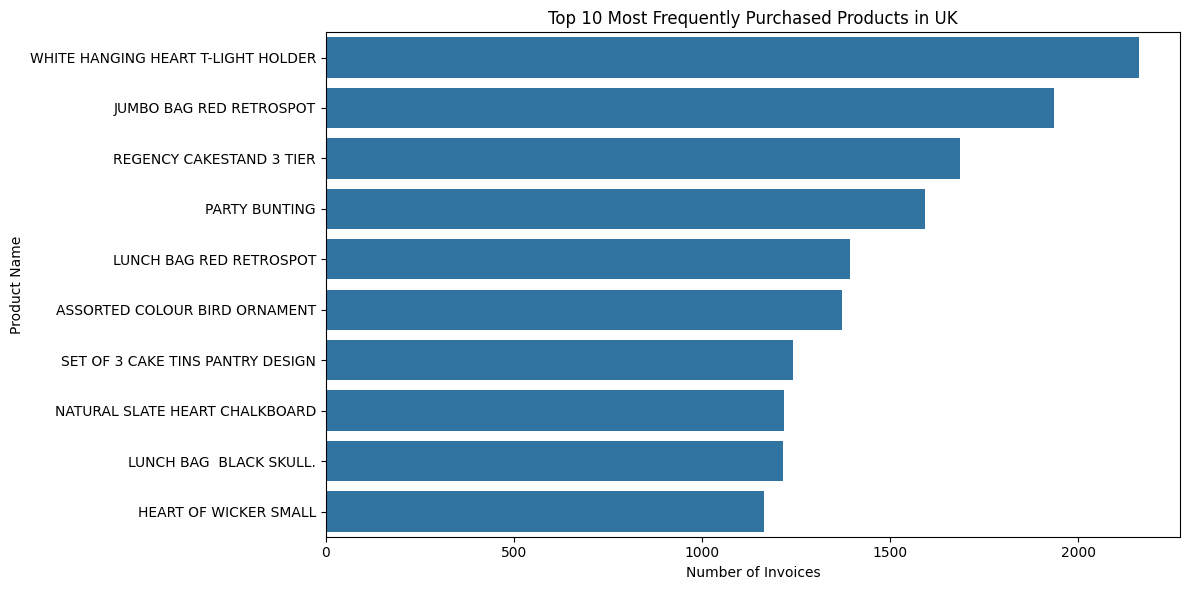

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate product purchase frequency
top_products = (
    df_uk.groupby('Description')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

# Display results
print("TOP 10 MOST FREQUENTLY PURCHASED PRODUCTS")
print(top_products)

# Visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title('Top 10 Most Frequently Purchased Products in UK')
plt.xlabel('Number of Invoices')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

BASKET SIZE ANALYSIS
---------------------------------------------
Total Baskets: 17917
Average Basket Size: 26.47
Median Basket Size: 15.0
Minimum Basket Size: 1
Maximum Basket Size: 1108


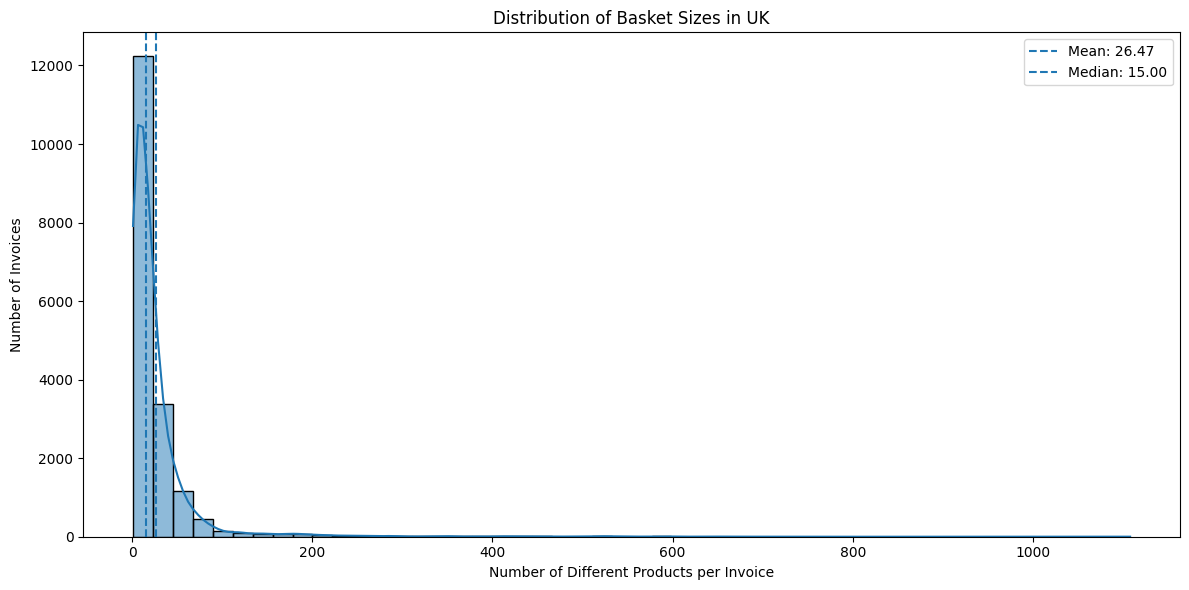

In [12]:
# Step 11.2: Basket Size Distribution

# Count unique products in each invoice
basket_sizes = df_uk.groupby('InvoiceNo')['Description'].nunique()

# Statistical analysis
print("BASKET SIZE ANALYSIS")
print("-" * 45)

print("Total Baskets:", len(basket_sizes))
print("Average Basket Size:", round(basket_sizes.mean(), 2))
print("Median Basket Size:", basket_sizes.median())
print("Minimum Basket Size:", basket_sizes.min())
print("Maximum Basket Size:", basket_sizes.max())

# Visualization
plt.figure(figsize=(12, 6))

sns.histplot(basket_sizes, bins=50, kde=True)

plt.axvline(
    basket_sizes.mean(),
    linestyle='--',
    label=f'Mean: {basket_sizes.mean():.2f}'
)

plt.axvline(
    basket_sizes.median(),
    linestyle='--',
    label=f'Median: {basket_sizes.median():.2f}'
)

plt.title('Distribution of Basket Sizes in UK')
plt.xlabel('Number of Different Products per Invoice')
plt.ylabel('Number of Invoices')
plt.legend()
plt.tight_layout()
plt.show()

MONTHLY TRANSACTION ANALYSIS
---------------------------------------------
InvoiceMonth
2010-12    1442
2011-01     968
2011-02     990
2011-03    1303
2011-04    1150
2011-05    1519
2011-06    1379
2011-07    1317
2011-08    1196
2011-09    1633
2011-10    1792
2011-11    2483
2011-12     745
Freq: M, Name: InvoiceNo, dtype: int64


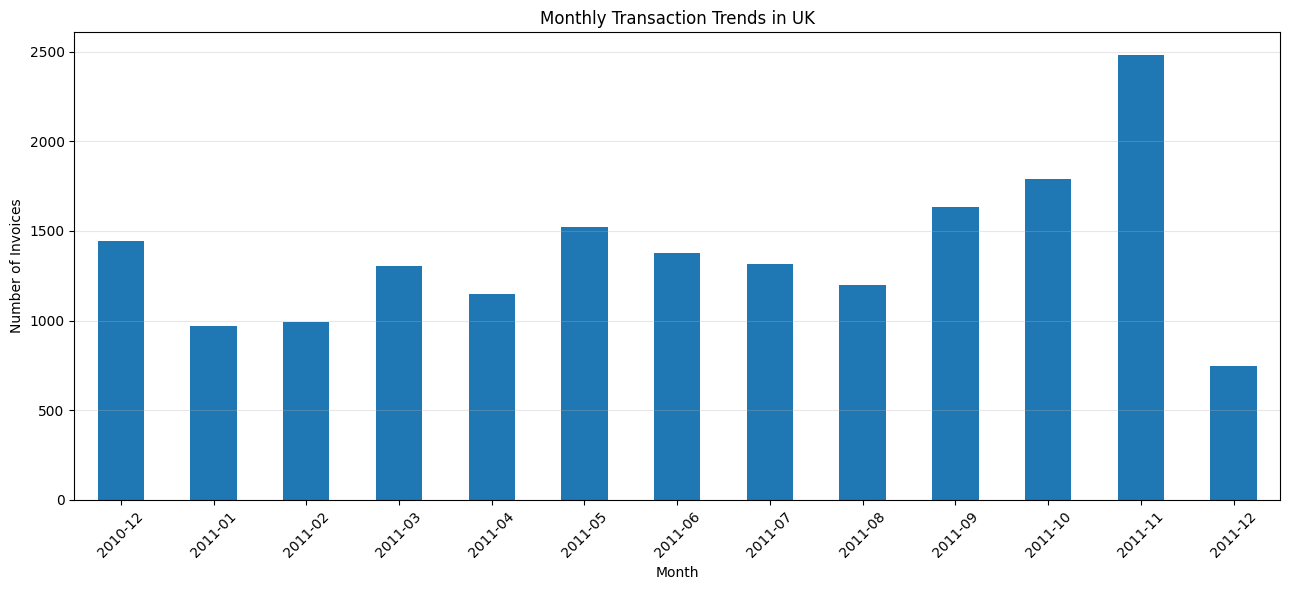

In [13]:
# Step 11.3: Monthly Transaction Analysis

# Extract month and year
df_uk['InvoiceMonth'] = df_uk['InvoiceDate'].dt.to_period('M')

# Count unique invoices per month
monthly_sales = (
    df_uk.groupby('InvoiceMonth')['InvoiceNo']
    .nunique()
)

print("MONTHLY TRANSACTION ANALYSIS")
print("-" * 45)
print(monthly_sales)

# Visualization
plt.figure(figsize=(13, 6))

monthly_sales.plot(kind='bar')

plt.title('Monthly Transaction Trends in UK')
plt.xlabel('Month')
plt.ylabel('Number of Invoices')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Step 12: Construct Transaction Basket Matrix

# Create a fresh basket matrix using product descriptions
basket = pd.crosstab(
    df_uk['InvoiceNo'],
    df_uk['Description']
)

# Convert to binary values
basket = (basket > 0).astype(int)

print("TRANSACTION BASKET MATRIX CREATED")
print("=" * 55)

print("Total Transactions:", basket.shape[0])
print("Total Products:", basket.shape[1])
print("Matrix Dimensions:", basket.shape)

# Find the 15 most frequently purchased products
top_products = basket.sum().sort_values(
    ascending=False
).head(15).index

# Select these products
sample = basket.loc[:, top_products].copy()

# Select invoices containing the maximum number
# of these popular products
sample['Total'] = sample.sum(axis=1)

sample = sample.sort_values(
    by='Total',
    ascending=False
)

# Display 15 representative transactions
display(sample.head(15).astype(int))

TRANSACTION BASKET MATRIX CREATED
Total Transactions: 17917
Total Products: 3994
Matrix Dimensions: (17917, 3994)


Description,WHITE HANGING HEART T-LIGHT HOLDER,JUMBO BAG RED RETROSPOT,REGENCY CAKESTAND 3 TIER,PARTY BUNTING,LUNCH BAG RED RETROSPOT,ASSORTED COLOUR BIRD ORNAMENT,SET OF 3 CAKE TINS PANTRY DESIGN,NATURAL SLATE HEART CHALKBOARD,LUNCH BAG BLACK SKULL.,HEART OF WICKER SMALL,JUMBO BAG PINK POLKADOT,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO STORAGE BAG SUKI,PACK OF 72 RETROSPOT CAKE CASES,PAPER CHAIN KIT 50'S CHRISTMAS,Total
InvoiceNo,,,,,,,,,,,,,,,,
573585,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,14
538524,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,13
537823,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,13
580730,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,12
580115,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,12
536592,1,1,1,0,1,1,0,0,1,1,1,1,1,1,1,12
536876,1,1,1,1,1,1,0,1,1,1,0,0,1,1,1,12
539437,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,12
564838,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,12


In [20]:
# Display a Representative Basket Matrix

# Select 15 most frequently purchased products
top_products = basket.sum().sort_values(
    ascending=False
).head(15).index

# Select these products from the complete matrix
sample = basket.loc[:, top_products]

# Select invoices containing at least 2 of these products
eligible_invoices = sample[
    sample.sum(axis=1) >= 2
]

# Randomly select 15 invoices
representative_sample = eligible_invoices.sample(
    n=15,
    random_state=42
)

print("REPRESENTATIVE TRANSACTION BASKET MATRIX")
print("=" * 55)

display(representative_sample.astype(int))

REPRESENTATIVE TRANSACTION BASKET MATRIX


Description,WHITE HANGING HEART T-LIGHT HOLDER,JUMBO BAG RED RETROSPOT,REGENCY CAKESTAND 3 TIER,PARTY BUNTING,LUNCH BAG RED RETROSPOT,ASSORTED COLOUR BIRD ORNAMENT,SET OF 3 CAKE TINS PANTRY DESIGN,NATURAL SLATE HEART CHALKBOARD,LUNCH BAG BLACK SKULL.,HEART OF WICKER SMALL,JUMBO BAG PINK POLKADOT,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO STORAGE BAG SUKI,PACK OF 72 RETROSPOT CAKE CASES,PAPER CHAIN KIT 50'S CHRISTMAS
InvoiceNo,,,,,,,,,,,,,,,
562923,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0
559342,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0
572897,1,1,0,0,0,0,1,0,0,1,1,1,1,0,0
578125,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
538064,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
546426,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
576520,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1
559937,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0
552839,0,1,0,1,1,0,0,0,0,0,1,0,0,0,0


In [21]:
!pip install -q mlxtend

In [22]:
# Import libraries for Market Basket Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import time
import warnings

from mlxtend.frequent_patterns import apriori, fpgrowth
from mlxtend.frequent_patterns import association_rules

warnings.filterwarnings('ignore')

print("All required libraries imported successfully!")
print("Apriori Algorithm: Ready")
print("FP-Growth Algorithm: Ready")
print("Association Rules: Ready")

All required libraries imported successfully!
Apriori Algorithm: Ready
FP-Growth Algorithm: Ready
Association Rules: Ready


In [23]:
# Step 14: Implement Apriori Algorithm

import time
from mlxtend.frequent_patterns import apriori

# Set minimum support
min_support = 0.02

print("APRIORI ALGORITHM EXECUTION")
print("=" * 50)

# Measure execution time
start_time = time.time()

frequent_itemsets_apriori = apriori(
    basket.astype(bool),
    min_support=min_support,
    use_colnames=True,
    max_len=3,
    low_memory=True
)

end_time = time.time()

apriori_time = end_time - start_time

print("Apriori Algorithm Executed Successfully!")
print("Minimum Support:", min_support)
print("Maximum Itemset Length: 3")
print("Execution Time:", round(apriori_time, 3), "seconds")

print("\nTotal Frequent Itemsets:",
      len(frequent_itemsets_apriori))

print("\nSample Frequent Itemsets:")

display(
    frequent_itemsets_apriori
    .sort_values('support', ascending=False)
    .head(15)
)

APRIORI ALGORITHM EXECUTION
Apriori Algorithm Executed Successfully!
Minimum Support: 0.02
Maximum Itemset Length: 3
Execution Time: 5.017 seconds

Total Frequent Itemsets: 404

Sample Frequent Itemsets:


,support,itemsets
282,0.120668,(WHITE HANGING HEART T-LIGHT HOLDER)
110,0.107998,(JUMBO BAG RED RETROSPOT)
205,0.094045,(REGENCY CAKESTAND 3 TIER)
166,0.088910,(PARTY BUNTING)
136,0.077692,(LUNCH BAG RED RETROSPOT)
17,0.076520,(ASSORTED COLOUR BIRD ORNAMENT)
226,0.069264,(SET OF 3 CAKE TINS PANTRY DESIGN)
148,0.068036,(NATURAL SLATE HEART CHALKBOARD)
129,0.067869,(LUNCH BAG BLACK SKULL.)
89,0.064966,(HEART OF WICKER SMALL)


In [24]:
# Step 15: Generate Association Rules

import inspect
from mlxtend.frequent_patterns import association_rules

print("GENERATING ASSOCIATION RULES")
print("=" * 50)

# Generate rules with minimum confidence of 50%
params = inspect.signature(association_rules).parameters

if 'num_itemsets' in params:
    rules_apriori = association_rules(
        frequent_itemsets_apriori,
        num_itemsets=len(basket),
        metric="confidence",
        min_threshold=0.50
    )
else:
    rules_apriori = association_rules(
        frequent_itemsets_apriori,
        metric="confidence",
        min_threshold=0.50
    )

print("Association Rules Generated Successfully!")
print("Minimum Confidence: 0.50")
print("Total Rules Generated:", len(rules_apriori))

# Display strongest rules by lift
if len(rules_apriori) > 0:

    rules_apriori = rules_apriori.sort_values(
        by='lift',
        ascending=False
    )

    display(
        rules_apriori[
            ['antecedents', 'consequents',
             'support', 'confidence', 'lift']
        ].head(15)
    )
else:
    print("No rules generated. We will review the thresholds.")

GENERATING ASSOCIATION RULES
Association Rules Generated Successfully!
Minimum Confidence: 0.50
Total Rules Generated: 79


,antecedents,consequents,support,confidence,lift
61,(WOODEN STAR CHRISTMAS SCANDINAVIAN),(WOODEN HEART CHRISTMAS SCANDINAVIAN),0.020539,0.768267,27.043308
60,(WOODEN HEART CHRISTMAS SCANDINAVIAN),(WOODEN STAR CHRISTMAS SCANDINAVIAN),0.020539,0.722986,27.043308
66,(PINK REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER, GREEN REGENC...",0.027460,0.700855,17.938877
63,"(ROSES REGENCY TEACUP AND SAUCER, GREEN REGENC...",(PINK REGENCY TEACUP AND SAUCER),0.027460,0.702857,17.938877
67,(GREEN REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER, PINK REGENCY...",0.027460,0.527897,17.354735
62,"(ROSES REGENCY TEACUP AND SAUCER, PINK REGENCY...",(GREEN REGENCY TEACUP AND SAUCER),0.027460,0.902752,17.354735
65,(ROSES REGENCY TEACUP AND SAUCER),"(PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY...",0.027460,0.514644,16.008477
64,"(PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY...",(ROSES REGENCY TEACUP AND SAUCER),0.027460,0.854167,16.008477
24,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.032148,0.618026,15.773743
23,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.032148,0.820513,15.773743


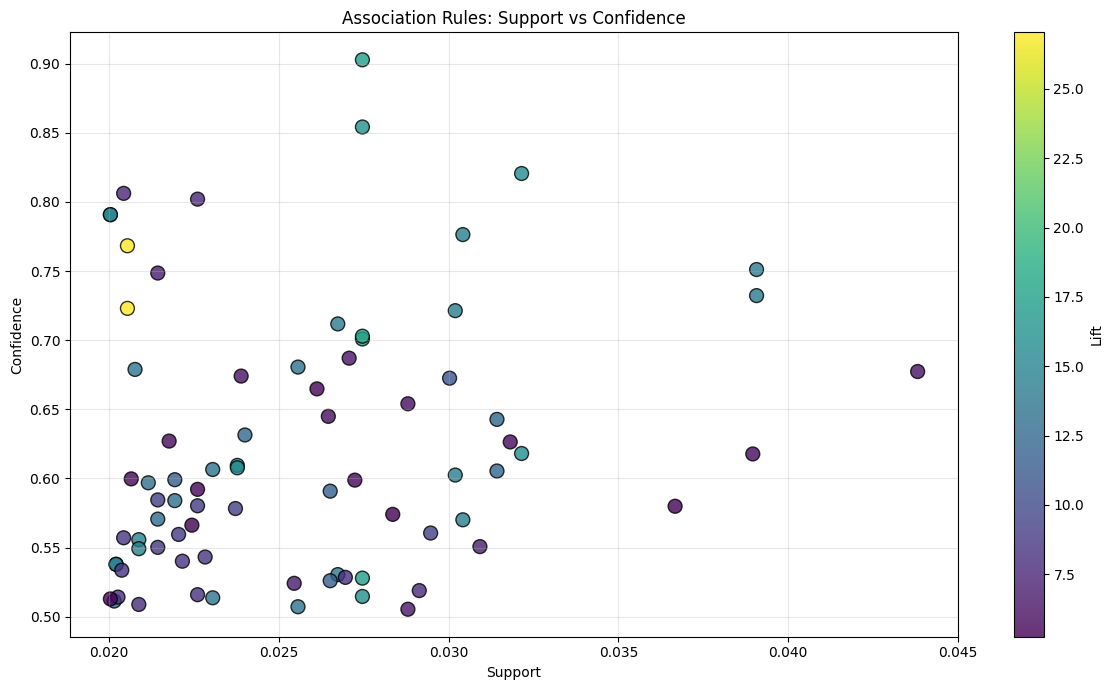

In [25]:
# Step 16: Association Rules Visualization

plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    rules_apriori['support'],
    rules_apriori['confidence'],
    c=rules_apriori['lift'],
    cmap='viridis',
    s=100,
    edgecolors='black',
    alpha=0.8
)

plt.colorbar(scatter, label='Lift')

plt.title('Association Rules: Support vs Confidence')
plt.xlabel('Support')
plt.ylabel('Confidence')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Step 17: Top 10 Association Rules

top_rules = rules_apriori.head(10).copy()

top_rules['Antecedents'] = top_rules['antecedents'].apply(
    lambda x: ', '.join(list(x))
)

top_rules['Consequents'] = top_rules['consequents'].apply(
    lambda x: ', '.join(list(x))
)

top_rules['support'] = top_rules['support'].round(4)
top_rules['confidence'] = top_rules['confidence'].round(4)
top_rules['lift'] = top_rules['lift'].round(4)

print("TOP 10 STRONGEST ASSOCIATION RULES")

display(
    top_rules[
        ['Antecedents', 'Consequents',
         'support', 'confidence', 'lift']
    ]
)

TOP 10 STRONGEST ASSOCIATION RULES


,Antecedents,Consequents,support,confidence,lift
61,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.0205,0.7683,27.0433
60,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.0205,0.7230,27.0433
66,PINK REGENCY TEACUP AND SAUCER,"ROSES REGENCY TEACUP AND SAUCER, GREEN REGENCY...",0.0275,0.7009,17.9389
63,"ROSES REGENCY TEACUP AND SAUCER, GREEN REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.0275,0.7029,17.9389
67,GREEN REGENCY TEACUP AND SAUCER,"ROSES REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.0275,0.5279,17.3547
62,"ROSES REGENCY TEACUP AND SAUCER, PINK REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.0275,0.9028,17.3547
65,ROSES REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY ...",0.0275,0.5146,16.0085
64,"PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.0275,0.8542,16.0085
24,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.0321,0.6180,15.7737
23,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0321,0.8205,15.7737


In [27]:
# Step 18: Implement FP-Growth Algorithm

from mlxtend.frequent_patterns import fpgrowth
import time

print("FP-GROWTH ALGORITHM EXECUTION")
print("=" * 50)

# Measure execution time
start_time = time.time()

frequent_itemsets_fp = fpgrowth(
    basket.astype(bool),
    min_support=0.02,
    use_colnames=True,
    max_len=3
)

end_time = time.time()

fpgrowth_time = end_time - start_time

print("FP-Growth Executed Successfully!")
print("Minimum Support: 0.02")
print("Maximum Itemset Length: 3")

print("Execution Time:",
      round(fpgrowth_time, 3), "seconds")

print("\nTotal Frequent Itemsets:",
      len(frequent_itemsets_fp))

print("\nTop 15 Frequent Itemsets:")

display(
    frequent_itemsets_fp
    .sort_values('support', ascending=False)
    .head(15)
)

FP-GROWTH ALGORITHM EXECUTION
FP-Growth Executed Successfully!
Minimum Support: 0.02
Maximum Itemset Length: 3
Execution Time: 13.715 seconds

Total Frequent Itemsets: 404

Top 15 Frequent Itemsets:


,support,itemsets
0,0.120668,(WHITE HANGING HEART T-LIGHT HOLDER)
59,0.107998,(JUMBO BAG RED RETROSPOT)
161,0.094045,(REGENCY CAKESTAND 3 TIER)
240,0.088910,(PARTY BUNTING)
19,0.077692,(LUNCH BAG RED RETROSPOT)
4,0.076520,(ASSORTED COLOUR BIRD ORNAMENT)
251,0.069264,(SET OF 3 CAKE TINS PANTRY DESIGN)
49,0.068036,(NATURAL SLATE HEART CHALKBOARD)
99,0.067869,(LUNCH BAG BLACK SKULL.)
50,0.064966,(HEART OF WICKER SMALL)


In [28]:
# Step 19: Algorithm Comparison

print("APRIORI VS FP-GROWTH COMPARISON")
print("=" * 55)

# Convert itemsets into comparable format
apriori_sets = {
    frozenset(row['itemsets']): row['support']
    for _, row in frequent_itemsets_apriori.iterrows()
}

fp_sets = {
    frozenset(row['itemsets']): row['support']
    for _, row in frequent_itemsets_fp.iterrows()
}

# Compare itemsets
common_itemsets = set(apriori_sets) & set(fp_sets)

print("Apriori Itemsets:", len(apriori_sets))
print("FP-Growth Itemsets:", len(fp_sets))
print("Common Itemsets:", len(common_itemsets))

print("Apriori Only:", len(set(apriori_sets) - set(fp_sets)))
print("FP-Growth Only:", len(set(fp_sets) - set(apriori_sets)))

# Compare support values
support_match = all(
    np.isclose(apriori_sets[item], fp_sets[item])
    for item in common_itemsets
)

print("\nSupport Values Match:", support_match)

print("\nExecution Time Comparison:")
print("Apriori:", round(apriori_time, 3), "seconds")
print("FP-Growth:", round(fpgrowth_time, 3), "seconds")

APRIORI VS FP-GROWTH COMPARISON
Apriori Itemsets: 404
FP-Growth Itemsets: 404
Common Itemsets: 404
Apriori Only: 0
FP-Growth Only: 0

Support Values Match: True

Execution Time Comparison:
Apriori: 5.017 seconds
FP-Growth: 13.715 seconds


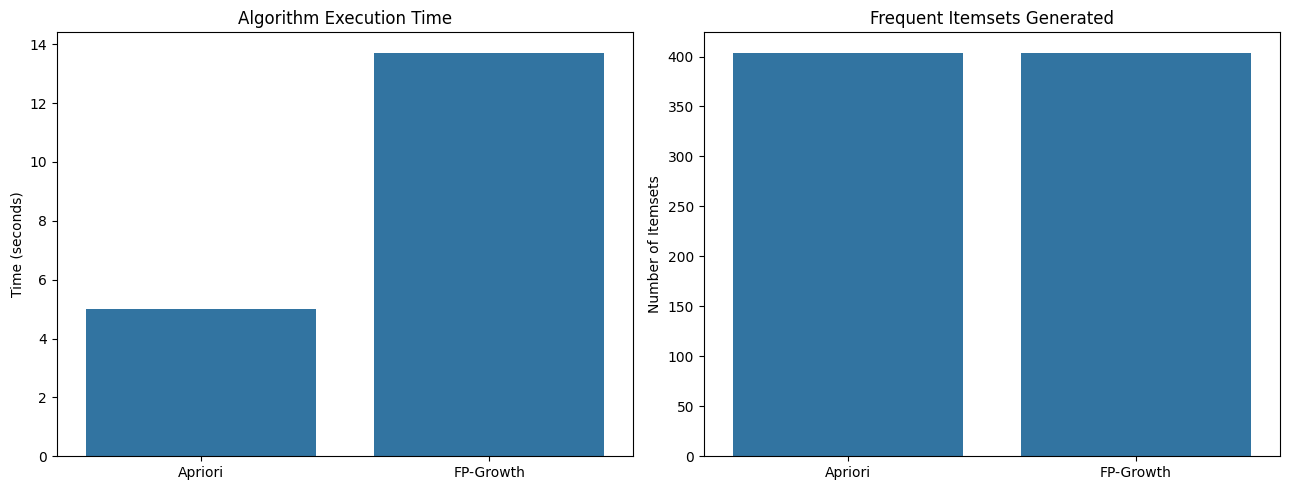

In [29]:
# Algorithm Performance Visualization

algorithms = ['Apriori', 'FP-Growth']

execution_times = [apriori_time, fpgrowth_time]

itemset_counts = [
    len(frequent_itemsets_apriori),
    len(frequent_itemsets_fp)
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    x=algorithms,
    y=execution_times,
    ax=axes[0]
)

axes[0].set_title('Algorithm Execution Time')
axes[0].set_ylabel('Time (seconds)')

sns.barplot(
    x=algorithms,
    y=itemset_counts,
    ax=axes[1]
)

axes[1].set_title('Frequent Itemsets Generated')
axes[1].set_ylabel('Number of Itemsets')

plt.tight_layout()
plt.show()

In [30]:
# Step 20: Generate FP-Growth Association Rules

print("FP-GROWTH ASSOCIATION RULE GENERATION")
print("=" * 50)

# Generate association rules
if 'num_itemsets' in inspect.signature(association_rules).parameters:

    rules_fp = association_rules(
        frequent_itemsets_fp,
        num_itemsets=len(basket),
        metric='confidence',
        min_threshold=0.50
    )

else:

    rules_fp = association_rules(
        frequent_itemsets_fp,
        metric='confidence',
        min_threshold=0.50
    )

# Sort rules by lift
rules_fp = rules_fp.sort_values(
    by='lift',
    ascending=False
)

print("Association Rules Generated Successfully!")
print("Minimum Confidence: 0.50")
print("Total FP-Growth Rules:", len(rules_fp))

print("\nTop 10 FP-Growth Association Rules:")

display(
    rules_fp[
        ['antecedents', 'consequents',
         'support', 'confidence', 'lift']
    ].head(10)
)

FP-GROWTH ASSOCIATION RULE GENERATION
Association Rules Generated Successfully!
Minimum Confidence: 0.50
Total FP-Growth Rules: 79

Top 10 FP-Growth Association Rules:


,antecedents,consequents,support,confidence,lift
61,(WOODEN STAR CHRISTMAS SCANDINAVIAN),(WOODEN HEART CHRISTMAS SCANDINAVIAN),0.020539,0.768267,27.043308
60,(WOODEN HEART CHRISTMAS SCANDINAVIAN),(WOODEN STAR CHRISTMAS SCANDINAVIAN),0.020539,0.722986,27.043308
71,(PINK REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER, GREEN REGENC...",0.027460,0.700855,17.938877
68,"(ROSES REGENCY TEACUP AND SAUCER, GREEN REGENC...",(PINK REGENCY TEACUP AND SAUCER),0.027460,0.702857,17.938877
72,(GREEN REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER, PINK REGENCY...",0.027460,0.527897,17.354735
67,"(ROSES REGENCY TEACUP AND SAUCER, PINK REGENCY...",(GREEN REGENCY TEACUP AND SAUCER),0.027460,0.902752,17.354735
70,(ROSES REGENCY TEACUP AND SAUCER),"(PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY...",0.027460,0.514644,16.008477
69,"(PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY...",(ROSES REGENCY TEACUP AND SAUCER),0.027460,0.854167,16.008477
64,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.032148,0.618026,15.773743
63,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.032148,0.820513,15.773743


In [32]:
# Step 21: Compare Association Rules

print("APRIORI VS FP-GROWTH RULE COMPARISON")
print("=" * 55)

# Convert rules into comparable sets
apriori_rules_set = set(
    zip(
        rules_apriori['antecedents'].apply(frozenset),
        rules_apriori['consequents'].apply(frozenset)
    )
)

fp_rules_set = set(
    zip(
        rules_fp['antecedents'].apply(frozenset),
        rules_fp['consequents'].apply(frozenset)
    )
)

print("Apriori Rules:", len(apriori_rules_set))
print("FP-Growth Rules:", len(fp_rules_set))

print("Common Rules:",
      len(apriori_rules_set & fp_rules_set))

print("Apriori Only:",
      len(apriori_rules_set - fp_rules_set))

print("FP-Growth Only:",
      len(fp_rules_set - apriori_rules_set))

print("\nAre Both Rule Sets Identical?",
      apriori_rules_set == fp_rules_set)

APRIORI VS FP-GROWTH RULE COMPARISON
Apriori Rules: 79
FP-Growth Rules: 79
Common Rules: 79
Apriori Only: 0
FP-Growth Only: 0

Are Both Rule Sets Identical? True


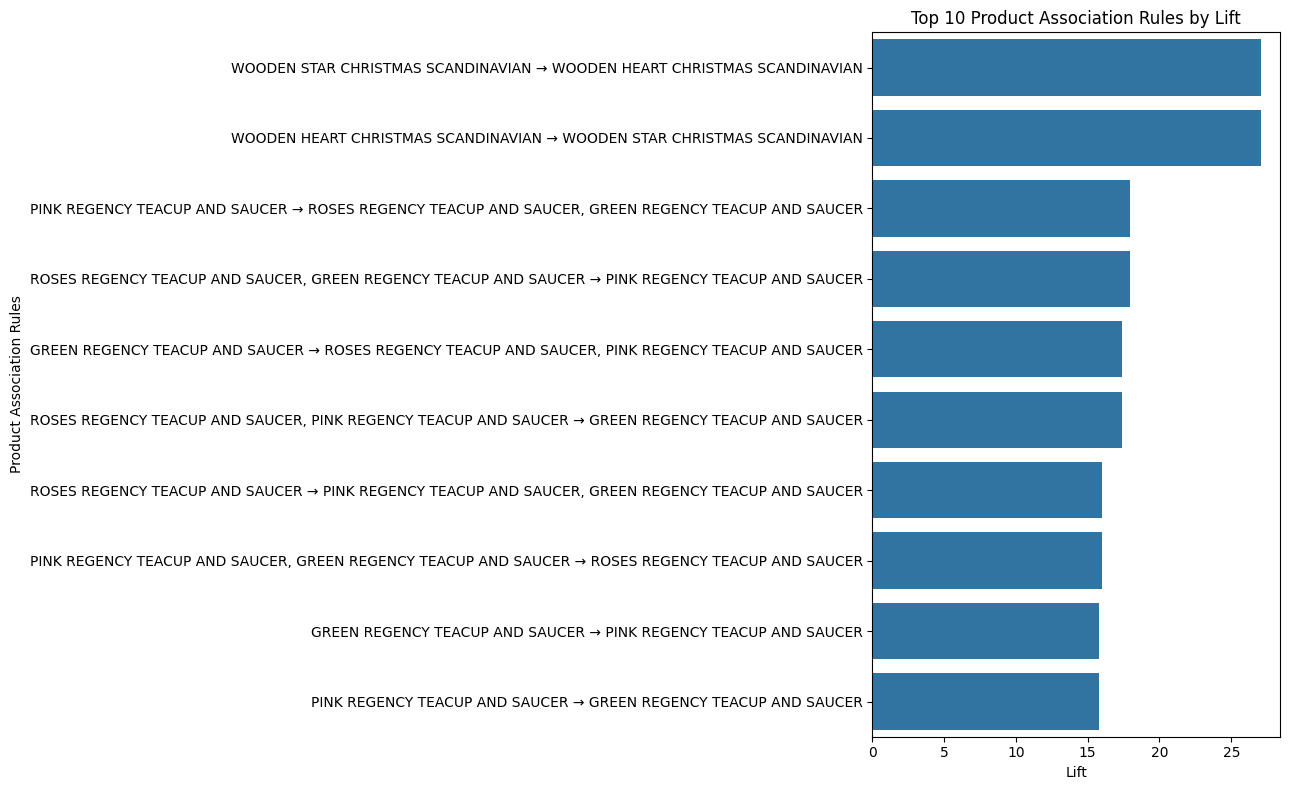

In [33]:
# Step 22: Top 10 Association Rules by Lift

top_10_rules = rules_apriori.sort_values(
    'lift', ascending=False
).head(10).copy()

top_10_rules['Rule'] = top_10_rules.apply(
    lambda row: (
        ', '.join(row['antecedents'])
        + ' → ' +
        ', '.join(row['consequents'])
    ),
    axis=1
)

plt.figure(figsize=(13, 8))

sns.barplot(
    data=top_10_rules,
    x='lift',
    y='Rule'
)

plt.title('Top 10 Product Association Rules by Lift')
plt.xlabel('Lift')
plt.ylabel('Product Association Rules')
plt.tight_layout()
plt.show()

In [34]:
# Step 23: Final Performance Evaluation

print("=" * 60)
print("FINAL ALGORITHM PERFORMANCE EVALUATION")
print("=" * 60)

comparison = pd.DataFrame({
    'Parameter': [
        'Frequent Itemsets',
        'Association Rules',
        'Execution Time (Seconds)'
    ],
    'Apriori': [
        len(frequent_itemsets_apriori),
        len(rules_apriori),
        round(apriori_time, 3)
    ],
    'FP-Growth': [
        len(frequent_itemsets_fp),
        len(rules_fp),
        round(fpgrowth_time, 3)
    ]
})

display(comparison)

print("\nRULE COMPARISON")
print("-" * 40)

print("Common Rules:",
      len(apriori_rules_set & fp_rules_set))

print("Are Both Rule Sets Identical:",
      apriori_rules_set == fp_rules_set)

print("\nBEST PERFORMING ALGORITHM (BY EXECUTION TIME):")

if apriori_time < fpgrowth_time:
    print("Apriori")
else:
    print("FP-Growth")

FINAL ALGORITHM PERFORMANCE EVALUATION


,Parameter,Apriori,FP-Growth
0,Frequent Itemsets,404.000,404.000
1,Association Rules,79.000,79.000
2,Execution Time (Seconds),5.017,13.715



RULE COMPARISON
----------------------------------------
Common Rules: 79
Are Both Rule Sets Identical: True

BEST PERFORMING ALGORITHM (BY EXECUTION TIME):
Apriori
